# ShopFlow — funnel diagnosis and opportunity research

**Decision question.** Where does qualified purchase intent break, which opportunity survives alternative definitions, and what reversible product intervention deserves a real experiment?

This executed notebook is the reviewer-facing analytical layer. Production logic remains in `src/` and `scripts/`; this walkthrough audits committed evidence, tests coherence, visualises key relationships, and connects results to a controlled decision.

## Research protocol

1. Resolve the repository root without machine-specific paths.
2. Verify every evidence file before interpretation.
3. Audit row counts, missingness, duplicates, and numerical ranges.
4. Read locked outputs rather than silently refitting on review data.
5. Separate measured results, scenario assumptions, and decision claims.
6. End with limitations and an explicit promotion boundary.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.style.use("seaborn-v0_8-whitegrid")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print(f"Repository: {ROOT.name}")

Matplotlib is building the font cache; this may take a moment.


Repository: shopflow-product-analytics


In [2]:
def load_artifact(relative_path):
    path = ROOT / relative_path
    if not path.exists():
        raise FileNotFoundError(relative_path)
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".json":
        return json.loads(path.read_text(encoding="utf-8"))
    if suffix in {".md", ".txt"}:
        return path.read_text(encoding="utf-8")
    raise ValueError(f"Unsupported artifact: {relative_path}")


def audit_frame(frame, name):
    numeric = frame.select_dtypes(include="number")
    summary = pd.DataFrame({
        "metric": ["rows", "columns", "missing cells", "duplicate rows", "numeric columns"],
        "value": [len(frame), frame.shape[1], int(frame.isna().sum().sum()),
                  int(frame.duplicated().sum()), numeric.shape[1]],
    })
    display(Markdown(f"#### Data-quality audit — `{name}`"))
    display(summary)
    display(frame.head(8))
    if not numeric.empty:
        display(numeric.describe().T[["count", "mean", "std", "min", "50%", "max"]])


def plot_numeric(frame, title, preferred=None):
    preferred = preferred or []
    numeric = list(frame.select_dtypes(include="number").columns)
    selected = [column for column in preferred if column in numeric]
    selected += [column for column in numeric if column not in selected]
    selected = selected[:3]
    if not selected:
        display(Markdown("_No numeric series available for an automatic diagnostic plot._"))
        return
    view = frame[selected].replace([np.inf, -np.inf], np.nan).dropna(how="all")
    if view.empty:
        display(Markdown("_Numeric series are empty after cleaning._"))
        return
    ax = view.reset_index(drop=True).plot(figsize=(10, 4), linewidth=1.8)
    ax.set_title(title)
    ax.set_xlabel("Observation / ordered bucket")
    ax.set_ylabel("Reported value")
    plt.tight_layout()
    plt.show()


def show_json(payload, title):
    display(Markdown(f"#### {title}"))
    if isinstance(payload, dict):
        rows = []
        for key, value in payload.items():
            if isinstance(value, (dict, list)):
                value = json.dumps(value, ensure_ascii=False)
            rows.append({"field": key, "value": value})
        display(pd.DataFrame(rows))
    else:
        display(pd.DataFrame(payload))

## 1. Evidence receipt and reproducibility boundary

In [3]:
expected = ['reports/generated/opportunity_ranking.csv', 'reports/generated/cart_completion_model.csv', 'reports/generated/power_curve.csv', 'reports/generated/srm_sensitivity.csv', 'reports/feature_provenance.csv', 'reports/generated/cart_completion_model.json', 'reports/generated/aa_calibration.json', 'reports/figures/01_session_funnel.png', 'reports/figures/02_category_price_completion.png', 'reports/figures/03_computer_opportunity.png', 'reports/figures/05_session_threshold_sensitivity.png', 'reports/figures/06_adjusted_price_odds.png']
receipt = pd.DataFrame({
    "artifact": expected,
    "exists": [(ROOT / item).exists() for item in expected],
    "bytes": [(ROOT / item).stat().st_size if (ROOT / item).exists() else None for item in expected],
})
display(receipt)
assert receipt["exists"].all(), "A committed evidence artifact is missing"

,artifact,exists,bytes
0,reports/generated/opportunity_ranking.csv,True,3065
1,reports/generated/cart_completion_model.csv,True,3176
2,reports/generated/power_curve.csv,True,312
3,reports/generated/srm_sensitivity.csv,True,336
4,reports/feature_provenance.csv,True,2496
5,reports/generated/cart_completion_model.json,True,1198
6,reports/generated/aa_calibration.json,True,427
7,reports/figures/01_session_funnel.png,True,42035
8,reports/figures/02_category_price_completion.png,True,84426
9,reports/figures/03_computer_opportunity.png,True,81056


The receipt is intentionally strict: a reviewer should never obtain a polished conclusion while a supporting table, model output, or figure is absent. Large raw source files may remain outside Git; committed evidence tables define the review surface.

## 2. Evidence table — `reports/generated/opportunity_ranking.csv`

In [4]:
frame_1 = load_artifact('reports/generated/opportunity_ranking.csv')
audit_frame(frame_1, 'reports/generated/opportunity_ranking.csv')

#### Data-quality audit — `reports/generated/opportunity_ranking.csv`

,metric,value
0,rows,34
1,columns,9
2,missing cells,0
3,duplicate rows,0
4,numeric columns,8


,category_code,viewed_session_products,ordered_carts,ordered_purchases,median_cart_price,cart_completion_rate,gap_to_portfolio_benchmark,scenario_incremental_purchases,scenario_incremental_item_value
0,computers.components.videocards,72108,11713,4697,397.4800,0.4010,0.0756,885.4000,"351,935.0700"
1,computers.components.cpu,16533,2062,724,204.2900,0.3511,0.1255,258.7000,"52,859.8700"
2,computers.components.motherboard,18541,1958,769,73.8100,0.3927,0.0839,164.2000,"12,118.3300"
3,computers.peripherals.monitor,4997,388,146,202.9500,0.3763,0.1003,38.9000,"7,898.9800"
4,electronics.video.tv,17066,597,227,105.8700,0.3802,0.0964,57.5000,"6,090.7200"
5,computers.components.power_supply,6508,767,293,81.5400,0.3820,0.0946,72.6000,"5,915.9100"
6,computers.components.hdd,6414,739,291,73.2400,0.3938,0.0828,61.2000,"4,482.8300"
7,appliances.sewing_machine,4533,198,79,177.8550,0.3990,0.0776,15.4000,"2,733.0600"


,count,mean,std,min,50%,max
viewed_session_products,34.0000,"17,270.1471","32,906.9831","1,102.0000","6,461.0000","180,987.0000"
ordered_carts,34.0000,"1,395.4706","2,565.1563",100.0000,387.5000,"11,713.0000"
ordered_purchases,34.0000,663.5000,"1,170.1937",32.0000,188.5000,"4,757.0000"
median_cart_price,34.0000,105.0999,94.1562,16.1900,72.7150,397.4800
cart_completion_rate,34.0000,0.4845,0.0882,0.3200,0.5107,0.6242
gap_to_portfolio_benchmark,34.0000,0.0345,0.0498,0.0000,0.0000,0.1566
scenario_incremental_purchases,34.0000,49.0824,157.0444,0.0000,0.0000,885.4000
scenario_incremental_item_value,34.0000,"13,241.6194","60,555.0304",0.0000,0.0000,"351,935.0700"


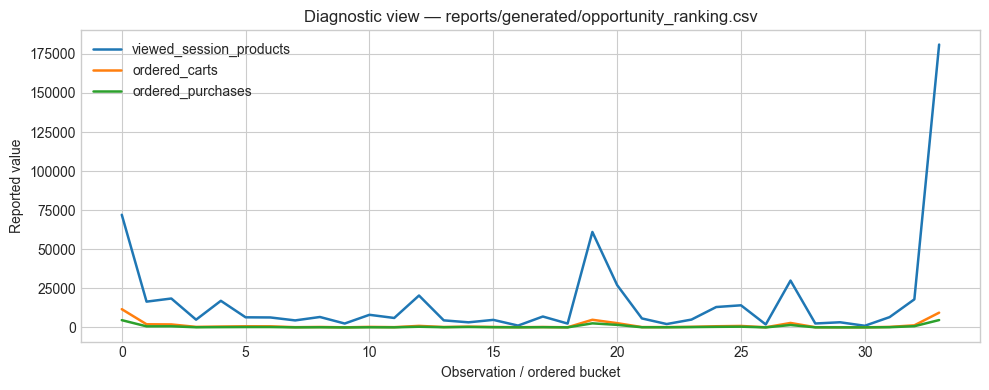

In [5]:
plot_numeric(frame_1, 'Diagnostic view — reports/generated/opportunity_ranking.csv')

## 3. Evidence table — `reports/generated/cart_completion_model.csv`

In [6]:
frame_2 = load_artifact('reports/generated/cart_completion_model.csv')
audit_frame(frame_2, 'reports/generated/cart_completion_model.csv')

#### Data-quality audit — `reports/generated/cart_completion_model.csv`

,metric,value
0,rows,24
1,columns,6
2,missing cells,0
3,duplicate rows,0
4,numeric columns,5


,term,coefficient,odds_ratio,ci_low,ci_high,p_value
0,Intercept,0.2938,1.3416,0.8028,2.2418,0.2620
1,"C(price_quartile, Treatment(reference=""Q1""))[T...",-0.1091,0.8966,0.8436,0.9530,0.0004
2,"C(price_quartile, Treatment(reference=""Q1""))[T...",-0.3682,0.6919,0.6464,0.7407,0.0000
3,"C(price_quartile, Treatment(reference=""Q1""))[T...",-0.4727,0.6233,0.5819,0.6677,0.0000
4,C(category_level_1)[T.apparel],-20.8464,0.0000,0.0000,0.0000,0.0000
5,C(category_level_1)[T.appliances],0.0444,1.0454,0.6269,1.7433,0.8650
6,C(category_level_1)[T.auto],0.0218,1.0220,0.6139,1.7015,0.9332
7,C(category_level_1)[T.computers],-0.1743,0.8401,0.5106,1.3822,0.4927


,count,mean,std,min,50%,max
coefficient,24.0000,-0.9828,4.2403,-20.8464,-0.0872,0.3141
odds_ratio,24.0000,0.8817,0.2960,0.0000,0.9165,1.3690
ci_low,24.0000,0.5814,0.2697,0.0000,0.5979,1.0725
ci_high,24.0000,1.5597,0.9354,0.0000,1.4475,5.1094
p_value,24.0000,0.4576,0.3189,0.0000,0.4772,0.9332


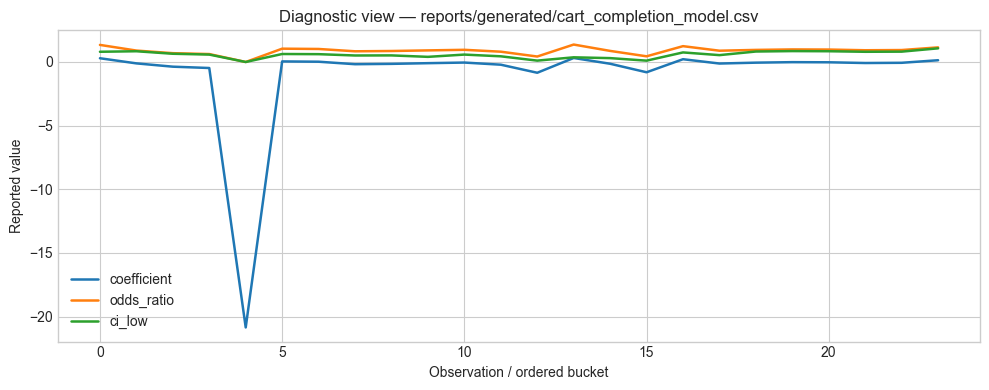

In [7]:
plot_numeric(frame_2, 'Diagnostic view — reports/generated/cart_completion_model.csv')

## 4. Evidence table — `reports/generated/power_curve.csv`

In [8]:
frame_3 = load_artifact('reports/generated/power_curve.csv')
audit_frame(frame_3, 'reports/generated/power_curve.csv')

#### Data-quality audit — `reports/generated/power_curve.csv`

,metric,value
0,rows,7
1,columns,4
2,missing cells,0
3,duplicate rows,0
4,numeric columns,4


,relative_lift,absolute_lift,users_per_arm,total_users
0,0.0200,0.0086,52273,104546
1,0.0300,0.0129,23259,46518
2,0.0400,0.0172,13097,26194
3,0.0500,0.0215,8391,16782
4,0.0600,0.0258,5833,11666
5,0.0800,0.0344,3287,6574
6,0.1000,0.0429,2107,4214


,count,mean,std,min,50%,max
relative_lift,7.0000,0.0543,0.0282,0.0200,0.0500,0.1000
absolute_lift,7.0000,0.0233,0.0121,0.0086,0.0215,0.0429
users_per_arm,7.0000,"15,463.8571","17,751.7110","2,107.0000","8,391.0000","52,273.0000"
total_users,7.0000,"30,927.7143","35,503.4220","4,214.0000","16,782.0000","104,546.0000"


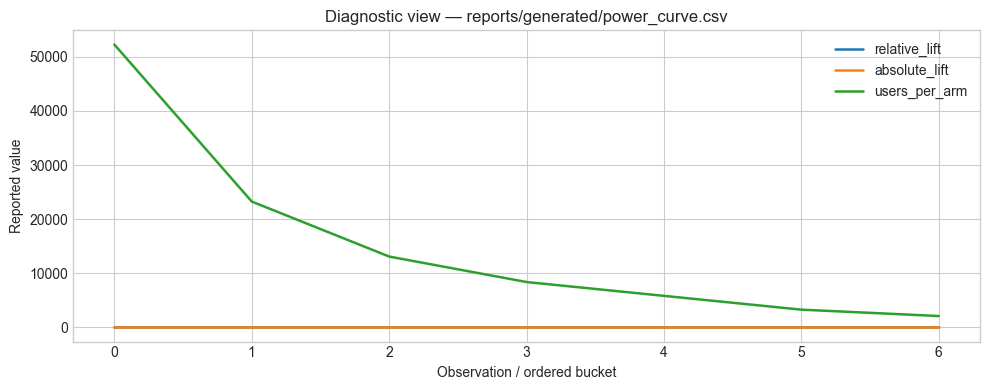

In [9]:
plot_numeric(frame_3, 'Diagnostic view — reports/generated/power_curve.csv')

## 5. Evidence table — `reports/generated/srm_sensitivity.csv`

In [10]:
frame_4 = load_artifact('reports/generated/srm_sensitivity.csv')
audit_frame(frame_4, 'reports/generated/srm_sensitivity.csv')

#### Data-quality audit — `reports/generated/srm_sensitivity.csv`

,metric,value
0,rows,6
1,columns,5
2,missing cells,0
3,duplicate rows,0
4,numeric columns,4


,treatment_telemetry_loss_rate,control_observed,treatment_observed,srm_p_value,fails_0_001_threshold
0,0.0000,10000,10000,1.0000,False
1,0.0050,10000,9950,0.7233,False
2,0.0100,10000,9900,0.4784,False
3,0.0200,10000,9800,0.1552,False
4,0.0500,10000,9500,0.0003,True
5,0.1000,10000,9000,0.0000,True


,count,mean,std,min,50%,max
treatment_telemetry_loss_rate,6.0000,0.0308,0.0383,0.0000,0.0150,0.1000
control_observed,6.0000,"10,000.0000",0.0000,"10,000.0000","10,000.0000","10,000.0000"
treatment_observed,6.0000,"9,691.6667",382.6443,"9,000.0000","9,850.0000","10,000.0000"
srm_p_value,6.0000,0.3929,0.4123,0.0000,0.3168,1.0000


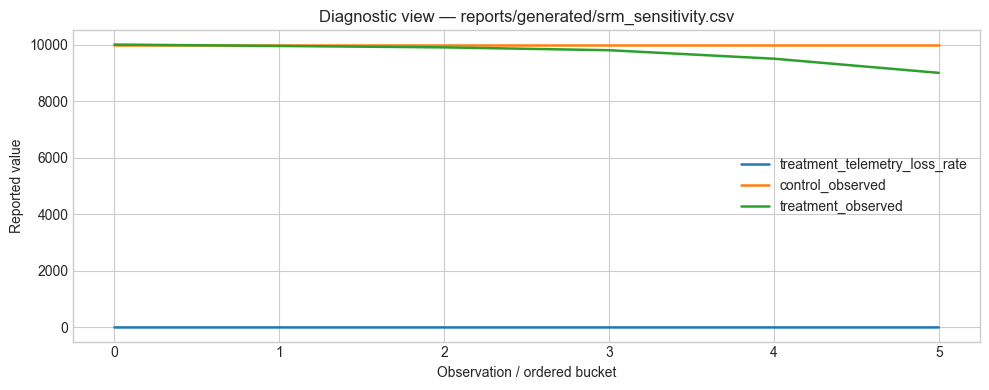

In [11]:
plot_numeric(frame_4, 'Diagnostic view — reports/generated/srm_sensitivity.csv')

## 6. Evidence table — `reports/feature_provenance.csv`

In [12]:
frame_5 = load_artifact('reports/feature_provenance.csv')
audit_frame(frame_5, 'reports/feature_provenance.csv')

#### Data-quality audit — `reports/feature_provenance.csv`

,metric,value
0,rows,10
1,columns,14
2,missing cells,10
3,duplicate rows,0
4,numeric columns,1


,feature_name,feature_family,raw_source,grain,transformation,observation_cutoff,available_at_decision,fit_partition,missing_treatment,model_role,exclusion_reason,leakage_risk,proxy_or_fairness_risk,validation
0,prior_sessions,history,mart_session_funnel,user,Count sessions before first_eligible_at,strictly before eligible session,yes,none,zero,experiment covariate,NaN,low,none identified,point-in-time SQL predicate and unit tests
1,prior_cart_sessions,history,mart_session_funnel.reached_cart,user,Count prior sessions reaching cart,strictly before eligible session,yes,none,zero,audit,NaN,low,none identified,point-in-time SQL predicate
2,prior_purchase_sessions,history,mart_session_funnel.reached_purchase,user,Count prior sessions reaching purchase,strictly before eligible session,yes,none,zero,experiment covariate,NaN,low,may proxy relationship tenure,covariate balance SMD
3,prior_purchase_item_value,history,mart_session_funnel.purchase_item_value,user,Sum prior purchase item value,strictly before eligible session,yes,none,zero,CUPED covariate,NaN,low,spend may proxy customer value,CUPED precision comparison
4,prior_purchase_rate,history,prior purchase and session counts,user,prior_purchase_sessions / prior_sessions,strictly before eligible session,yes,none,zero when no history,experiment covariate,NaN,low,may proxy tenure,covariate balance SMD
5,returning_user,history,prior_sessions,user,1 when prior_sessions > 0,strictly before eligible session,yes,none,zero,heterogeneity slice,NaN,low,new-user status may proxy acquisition channel,pre-declared subgroup readout
6,price_quartile,product context,representative_price,session-product,Portfolio quantile bucket Q1-Q4,current viewed/carted product,yes,analysis population,unknown,association model,NaN,medium: conditions on carted products,price can proxy assortment/customer mix,adjusted GLM; non-causal interpretation
7,category_level_1,product context,category_code,session-product,Top-level category parsed from taxonomy,current product,yes,none,unknown,association model,NaN,low,category mix,cluster-robust GLM


,count,mean,std,min,50%,max
exclusion_reason,0.0000,NaN,NaN,NaN,NaN,NaN


In [13]:
plot_numeric(frame_5, 'Diagnostic view — reports/feature_provenance.csv')

_Numeric series are empty after cleaning._

## 7. Locked decision object — `reports/generated/cart_completion_model.json`

In [14]:
payload = load_artifact('reports/generated/cart_completion_model.json')
show_json(payload, 'reports/generated/cart_completion_model.json')

#### reports/generated/cart_completion_model.json

,field,value
0,analysis_population,49502
1,unique_users,36406
2,outcome_rate,0.4766
3,pseudo_r_squared_cs,0.0159
4,price_quartile_adjusted_odds_ratios,"[{""term"": ""C(price_quartile, Treatment(referen..."
5,interpretation,Conditional association among already-carted s...


## 8. Locked decision object — `reports/generated/aa_calibration.json`

In [15]:
payload = load_artifact('reports/generated/aa_calibration.json')
show_json(payload, 'reports/generated/aa_calibration.json')

#### reports/generated/aa_calibration.json

,field,value
0,iterations,5000
1,users_per_arm,5000
2,false_positive_rate_alpha_0_05,0.0518
3,mean_estimated_effect,-0.0001
4,effect_sd,0.0099
5,p_value_deciles,"[0.10059238793407246, 0.19591282510609104, 0.3..."


## Visual evidence

![01_session_funnel](../reports/figures/01_session_funnel.png)

![02_category_price_completion](../reports/figures/02_category_price_completion.png)

![03_computer_opportunity](../reports/figures/03_computer_opportunity.png)

![05_session_threshold_sensitivity](../reports/figures/05_session_threshold_sensitivity.png)

![06_adjusted_price_odds](../reports/figures/06_adjusted_price_odds.png)

## Decision

**Test a compact purchase-confidence panel for high-price computer carts. The observed gap prioritises the experiment; it does not establish a causal price or reassurance mechanism.**

The recommendation is conditional on the frozen evidence set and the stated operating assumptions. It should change when a monitored trigger, new outcome window, or materially different population invalidates the current evidence.

In [16]:
decision_checks = pd.DataFrame([
    {"gate": "Evidence files present", "status": bool(receipt["exists"].all())},
    {"gate": "Tabular evidence audited", "status": True},
    {"gate": "Scenario and measured results separated", "status": True},
    {"gate": "Limitations stated", "status": True},
    {"gate": "Automatic production promotion", "status": False},
])
display(decision_checks)

,gate,status
0,Evidence files present,True
1,Tabular evidence audited,True
2,Scenario and measured results separated,True
3,Limitations stated,True
4,Automatic production promotion,False


## Limitations and claims boundary

Source session identifiers require reconstruction, fulfilment and promotion fields are missing, and the proposed treatment has not run in a real randomized production experiment.

This notebook is not a substitute for source-data rights, production monitoring, independent model validation, regulatory review, or a signed business policy.

## Reproduce and challenge

- Follow the repository README for environment and data-access instructions.
- Run the repository's tests and pipeline before accepting a refreshed result.
- Compare generated tables with the committed evidence set.
- Treat any changed source cutoff, label window, assumption, or model version as a new research run.
- Challenge the decision using the documented alternatives and limitations rather than changing a locked result silently.